<center>Department of Electronic and Telecommunication Engineering</center>
<center> University of Moratuwa </center>
<h3><center>EN3160: Image Processing and Machine Vision</center></h3>
<h2><b><center>Assignment 1: Point Operations and Spatial Filtering</center></h2></b>
<center>Aroshana H. A. P. 230058N (230058n_a01)<br></center>
<center>14th September 2026<br></center>
<center><a href="https://github.com/aroshana188/Image-Processing-and-Machine-Vision.git">Assignment Github Repository</a></center>

---

<h3><b>A. Graph Plotting Program using Matplotlib

To reduce redundant code, a generalized 1x3 plotting function was developed. The original input image, the applied mathematical transformation, and the final output image are passed to this function. These three elements are then automatically formatted and displayed side-by-side to ensure a consistent and clear layout across the report.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2 as cv

def plot_1x3(img_in, plot_data, img_out, title_in='Original Image', title_mid='Transformation Curve', 
             title_out='Transformed Image', xlabel='Input Intensity', ylabel='Output Intensity',
             line_color='maroon', x_data=None, show_reference_line=False):
    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    
    if len(img_in.shape) == 2:  
        axes[0].imshow(img_in, cmap='gray', vmin=0, vmax=255)
    else:  
        axes[0].imshow(img_in)
    axes[0].set_title(title_in)
    axes[0].axis('off')
    
    if x_data is not None:
        axes[1].plot(x_data, plot_data, color=line_color, label='Transform')
    else:
        axes[1].plot(plot_data, color=line_color, label='Transform')
        
    if show_reference_line:
        ref_x = x_data if x_data is not None else np.arange(len(plot_data))
        axes[1].plot(ref_x, ref_x, color='black', linestyle='--', alpha=0.4, label='y = x')
        axes[1].legend()

    axes[1].set_title(title_mid)
    axes[1].set_xlabel(xlabel)
    axes[1].set_ylabel(ylabel)
    
    max_x = 255 if x_data is None else max(x_data)
    axes[1].set_xlim(0, max_x)
    axes[1].set_ylim(0, 255)
    axes[1].set_aspect('equal')
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    # --- Plot 3: Output Image ---
    if len(img_out.shape) == 2:  
        axes[2].imshow(img_out, cmap='gray', vmin=0, vmax=255)
    else:  
        axes[2].imshow(img_out)
    axes[2].set_title(title_out)
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

<h3><b>Q1. Piecewise Linear Intensity Transformation

A piecewise linear transformation was defined using a specific set of coordinate breakpoints. A Look Up Table (LUT) was generated from these breakpoints and was subsequently applied to the original grayscale image to alter its intensity profile.

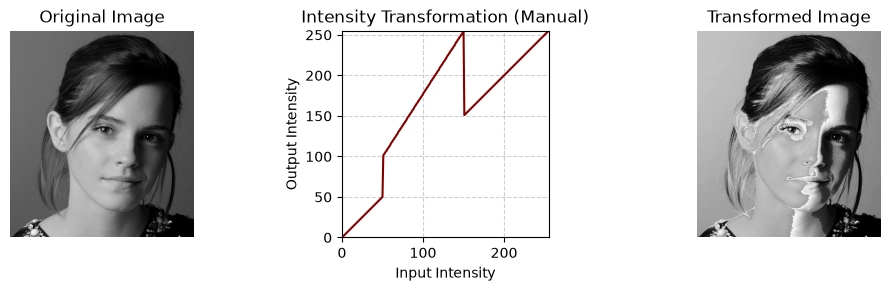

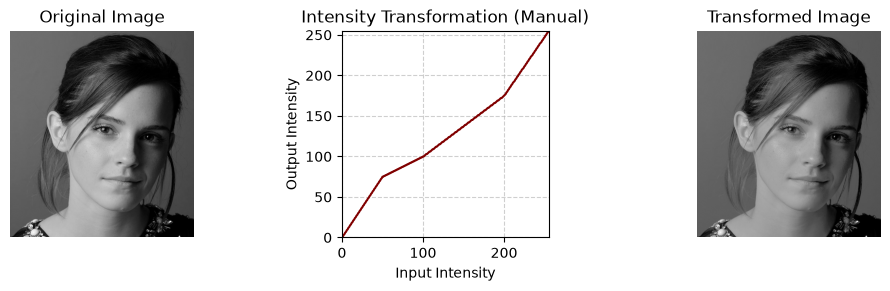

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def intensity_transform(im, breakpoints):
    c = breakpoints
    lut = np.array([], dtype='uint8')
    seg_count = len(c)
    for i in range(seg_count-1):
        if c[i,0]==c[i+1,0] and c[i,1]!=c[i+1,1]:
            continue
        elif i == 0:
            t = np.linspace(c[i,1], c[i+1,1], c[i+1,0] - c[i,0] + 1).astype('uint8')
        else:
            m = (c[i+1,1] - c[i,1]) / (c[i+1,0] - c[i,0])
            t = np.linspace(c[i,1]+m, c[i+1,1], c[i+1,0]-c[i,0]).astype('uint8')
        lut = np.concatenate((lut, t), axis=0)
    transformed_im = cv.LUT(im, lut)
    return transformed_im, lut

image_path = 'C:/Users/PC/University/Semester_5/Image Processing and Machne Vision/Assignment_1/emma.jpg'
img_orig = cv.imread(image_path, cv.IMREAD_GRAYSCALE)
assert img_orig is not None

breaking = np.array([(0,0), (50,50), (50,100), (150,255), (150,150), (255,255)])
breaking_1 = np.array([(0,0), (50,75), (100,100), (200,175), (255,255)])

if img_orig is not None:
    img_transformed_1, transform_lut_1 = intensity_transform(img_orig, breaking)
    plot_1x3(img_in=img_orig, plot_data=transform_lut_1, img_out=img_transformed_1, title_mid='Intensity Transformation (Manual)')

    img_transformed_1, transform_lut_1 = intensity_transform(img_orig, breaking_1)
    plot_1x3(img_in=img_orig,  plot_data=transform_lut_1, img_out=img_transformed_1,title_mid='Intensity Transformation (Manual)')

else:
    print("Error: Image not found. Check the file path.")

It is observed that the transformation successfully maps input intensities to new output values based on the defined curve. By utilizing a piecewise approach, precise and targeted adjustments are made to the image contrast, allowing specific intensity ranges to be expanded or compressed as needed.

<h3><b>Q2. Medical Image Contrast Stretching

Two separate piecewise linear transformations were defined to isolate specific brain tissues from a proton density background slice. The first transformation was applied to accentuate the white matter, while the second was applied to highlight the gray matter.

The image histogram was first generated and analyzed to identify the specific pixel intensity ranges of different brain tissues. Using the peaks observed in this histogram, two separate piecewise linear transformations were defined. The first transformation was applied to isolate and accentuate the white matter, while the second was applied to highlight the gray matter.

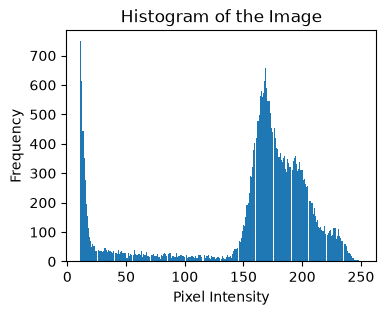

In [3]:
# load the original image
image_path = 'C:/Users/PC/University/Semester_5/Image Processing and Machne Vision/Assignment_1/brain.jpeg'
img_orig = cv.imread(image_path, cv.IMREAD_GRAYSCALE)
assert img_orig is not None

brain_pixels = img_orig[img_orig > 10]

plt.figure(figsize=(4, 3))
plt.hist(brain_pixels, bins=256)
plt.title("Histogram of the Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

The generated histogram reveals distinct intensity peaks that correspond to different physical tissues within the brain scan. By analyzing these specific peaks, exact threshold values were chosen to separate the white and gray matter. A steep transformation slope was then applied strictly to these narrow intensity bands. As a result, the contrast was successfully stretched in the targeted regions, revealing structural details that were originally too compressed to see clearly.

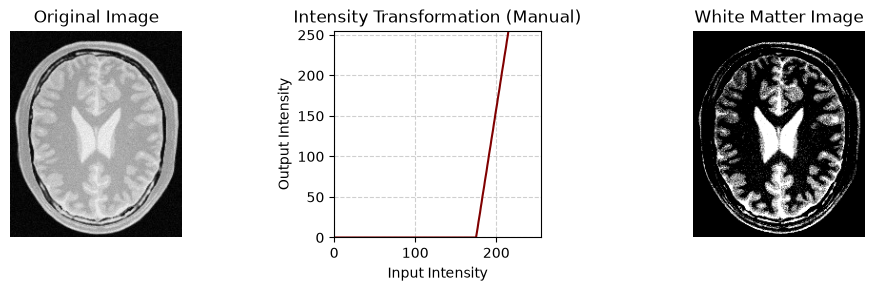

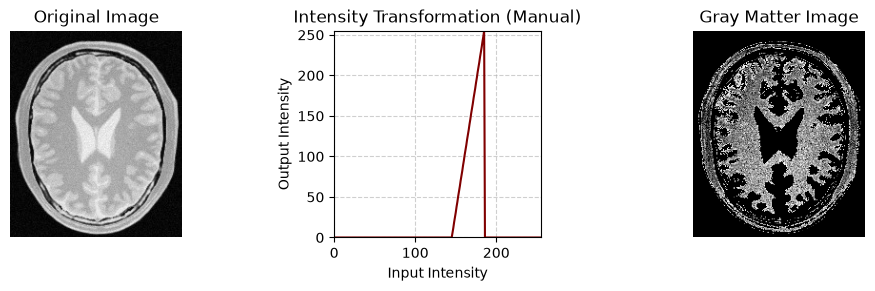

In [4]:
breaking_wm = np.array([(0,0), (175,0), (215,255), (255,255)])
breaking_gm = np.array([(0,0), (145,0), (185,255), (185,0), (255,0)])

if img_orig is not None:
    img_wm, lut_wm = intensity_transform(img_orig, breaking_wm)
    plot_1x3(img_in=img_orig, plot_data=lut_wm, img_out=img_wm,title_mid='Intensity Transformation (Manual)',title_out='White Matter Image')

    img_gm, lut_gm = intensity_transform(img_orig, breaking_gm)
    plot_1x3(img_in=img_orig,plot_data=lut_gm, img_out=img_gm, title_mid='Intensity Transformation (Manual)', title_out='Gray Matter Image')

else:
    print("Error: Image not found. Check the file path.")

By manipulating the slope of the transformation curve, specific intensity ranges were successfully expanded. A steep slope was applied to the narrow intensity bands corresponding to the white and gray matter. As a result, the contrast was significantly stretched in those specific regions, revealing structural details in the medical scan that were previously obscured.

<h3><b>Q3. Gamma Correction in L*a*b* Color Space

First, we converted the original RGB image into the L\*a\*b\* color space. Then, we applied gamma correction only to the lightness channel (L) using a Look-Up Table (LUT) before converting it back to RGB.

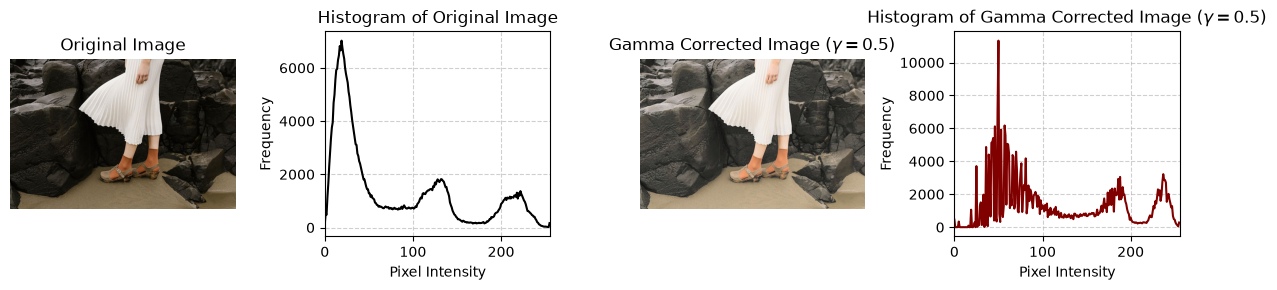

In [16]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

image_path = 'C:/Users/PC/University/Semester_5/Image Processing and Machne Vision/Assignment_1/gamma.jpeg'
img_orig = cv.imread(image_path)
assert img_orig is not None
img_lab = cv.cvtColor(img_orig, cv.COLOR_BGR2Lab)
img_rgb = cv.cvtColor(img_orig, cv.COLOR_BGR2RGB)

gamma = 0.5
lut = np.array([(i/255.0)**(gamma)*255.0 for i in np.arange(0,256)]).astype('uint8')

l, a, b = cv.split(img_lab)
l_gamma_corrected = cv.LUT(l, lut)
img_lab_corrected = cv.merge((l_gamma_corrected, a, b))
img_rgb_corrected = cv.cvtColor(img_lab_corrected, cv.COLOR_Lab2RGB)

hist_original = cv.calcHist([img_rgb], [0], None, [256], [0, 256])
hist_corrected = cv.calcHist([img_rgb_corrected], [0], None, [256], [0, 256])

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

axes[0].imshow(img_rgb)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].plot(hist_original, color='black')
axes[1].set_title('Histogram of Original Image')
axes[1].set_xlabel('Pixel Intensity')
axes[1].set_ylabel('Frequency')
axes[1].set_xlim([0, 256])
axes[1].grid(True, linestyle='--', alpha=0.6)

axes[2].imshow(img_rgb_corrected)
axes[2].set_title(rf'Gamma Corrected Image ($\gamma = {gamma}$)')
axes[2].axis('off')

axes[3].plot(hist_corrected, color='maroon')
axes[3].set_title(rf'Histogram of Gamma Corrected Image ($\gamma = {gamma}$)')
axes[3].set_xlabel('Pixel Intensity')
axes[3].set_ylabel('Frequency')
axes[3].set_xlim([0, 256])
axes[3].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

The gamma correction is applied to the RGB channels. It alters the color balance and makes the image look unnatural. By switching to the L\*a\*b\* color space, the brightness (L) is separated  from the colors (a\* and b\*). 

When applying the correction only to the L channel, adjust the image's brightness while keeping the original colors perfectly intact. The histograms show that the corrected image has a much better spread of brightness levels.

<h3><b>Q4. Saturation Vibrance Enhancement

The original RGB image was converted into the HSV color space. The saturation channel (S) was isolated, and a custom vibrance formula was applied. This formula is designed to boost less saturated colors while protecting already saturated colors. Finally, the modified saturation channel was merged back, and the image was converted to RGB.

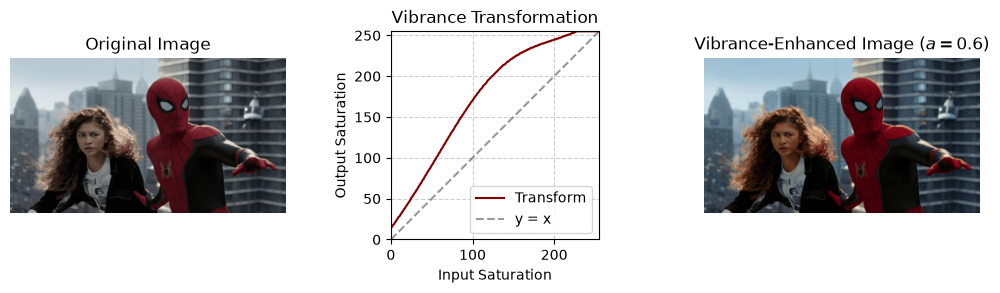

In [6]:
image_path = 'C:/Users/PC/University/Semester_5/Image Processing and Machne Vision/Assignment_1/spiderman.jpeg'
img_orig = cv.imread(image_path)
assert img_orig is not None

a = 0.6
sigma = 70

x = np.arange(256)
f_x = x + a * 128 * np.exp(-((x - 128)**2) / (2 * (sigma**2)))
lut = np.minimum(f_x, 255).astype('uint8')

img_rgb = cv.cvtColor(img_orig, cv.COLOR_BGR2RGB)
img_hsv = cv.cvtColor(img_orig, cv.COLOR_BGR2HSV)
h, s, v =cv.split(img_hsv)

s_enhanced = cv.LUT(s, lut)
img_hsv_enhanced = cv.merge((h, s_enhanced, v))
img_rgb_enhanced = cv.cvtColor(img_hsv_enhanced, cv.COLOR_HSV2RGB)

plot_1x3(img_in=img_rgb, plot_data=lut, img_out=img_rgb_enhanced,title_mid='Vibrance Transformation',title_out='Vibrance-Enhanced Image $(a=0.6)$',xlabel='Input Saturation',ylabel='Output Saturation',x_data=x, show_reference_line=True)

As shown in the transformation graph, lower saturation values are increased more aggressively than higher ones. This prevents the image from becoming overly saturated. A parameter value of $a = 0.6$ was chosen for the final output. This specific value was selected because a more vibrant and visually pleasing look is achieved without causing unnatural color shifts in the subjects.

<h3><b>Q5. Histrogram Equalization

The histogram and cumulative distribution function (CDF) of the original grayscale image were calculated. A custom equalization function was then applied to map the original pixel intensities to a wider range using the normalized CDF, replacing standard library functions.

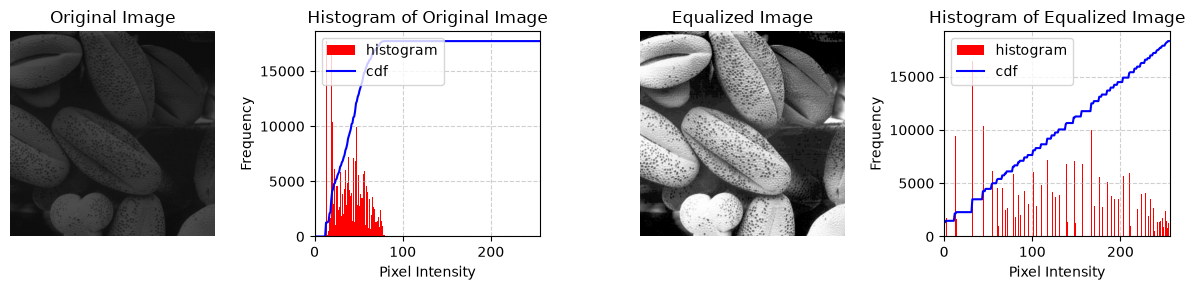

In [15]:
image_path = 'C:/Users/PC/University/Semester_5/Image Processing and Machne Vision/Assignment_1/shells.tif'
img = cv.imread(image_path, cv.IMREAD_GRAYSCALE)
assert img is not None, "Error: Image not found. Check the file path."

def custom_equalizeHist(img):
    """perform histrogram equalization"""
    hist, bins = np.histogram(img.flatten(), 256, [0, 256])  
    cdf = hist.cumsum()     # 2. Calculate CDF 
    cdf_m = np.ma.masked_equal(cdf, 0)    
    cdf_m = (cdf_m - cdf_m.min()) * 255 / (cdf_m.max() - cdf_m.min())    
    cdf_final = np.ma.filled(cdf_m, 0).astype('uint8')    
    equ = cv.LUT(img, cdf_final)  
    return equ

hist, bins = np.histogram(img.ravel(), 256, [0, 256])
cdf = hist.cumsum()
cdf_normalized = cdf * hist.max() / cdf.max()

equ = custom_equalizeHist(img)

hist_eq, bins_eq = np.histogram(equ.ravel(), 256, [0, 256]) 
cdf_eq = hist_eq.cumsum() 
cdf_normalized_2 = cdf_eq * hist_eq.max() / cdf_eq.max()

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].hist(img.flatten(), bins=256, range=[0, 256], color='r', label='histogram')
axes[1].plot(cdf_normalized, color='b', label='cdf')
axes[1].set_xlim([0, 256])
axes[1].legend(loc='upper left')
axes[1].set_title('Histogram of Original Image')
axes[1].set_xlabel('Pixel Intensity')
axes[1].set_ylabel('Frequency')
axes[1].grid(True, linestyle='--', alpha=0.6)

axes[2].imshow(equ, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Equalized Image')
axes[2].axis('off')

axes[3].hist(equ.flatten(), bins=256, range=[0, 256], color='r', label='histogram')
axes[3].plot(cdf_normalized_2, color='b', label='cdf')
axes[3].set_xlim([0, 256])
axes[3].legend(loc='upper left')
axes[3].set_title('Histogram of Equalized Image')
axes[3].set_xlabel('Pixel Intensity')
axes[3].set_ylabel('Frequency')
axes[3].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Based on the initial histogram, it is observed that the original pixel intensities are compressed into a narrow, low contrast range. After the custom equalization is applied, the pixel values are distributed much more evenly across the entire 0 - 255 spectrum. As a result, the global contrast of the image is significantly enhanced, revealing details and textures that were previously hidden.

<h3><b>Q6. Histrogram Equalization for the Foreground

The original image was converted into the HSV color space so the brightness could be isolated. A binary mask was generated using Otsu's thresholding to separate the main subject from the dark background. Histogram equalization was then applied exclusively to the foreground pixels before the final image was reconstructed.

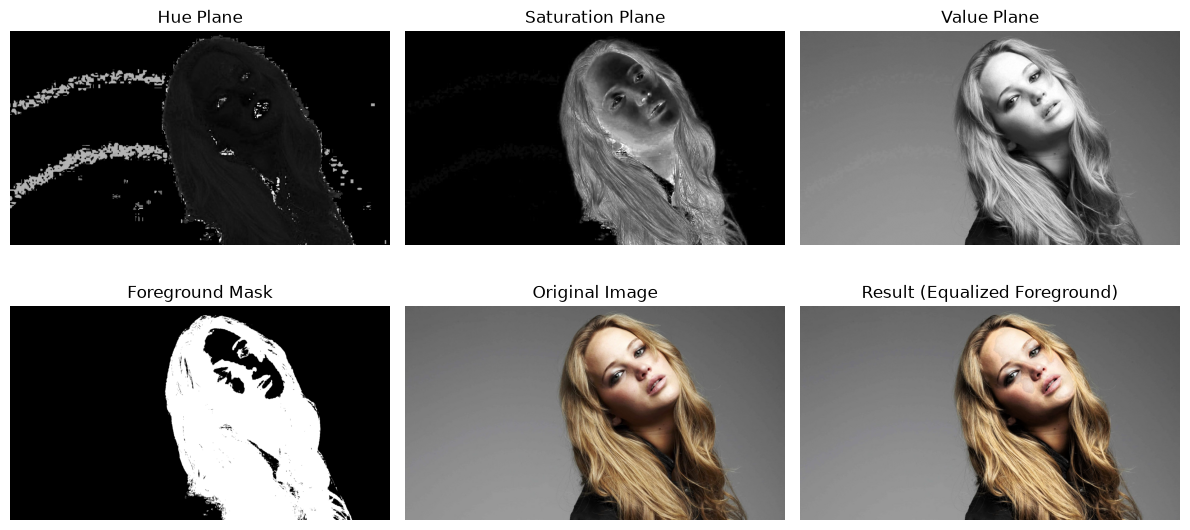

In [8]:
image_path = 'C:/Users/PC/University/Semester_5/Image Processing and Machne Vision/Assignment_1/histrogram.jpeg'
img_orig = cv.imread(image_path)
assert img_orig is not None

img_rgb = cv.cvtColor(img_orig, cv.COLOR_BGR2RGB)
img_hsv = cv.cvtColor(img_orig, cv.COLOR_BGR2HSV)
h, s, v =cv.split(img_hsv)

thresh, mask = cv.threshold(s, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
mask_inv = cv.bitwise_not(mask)
fg_v = cv.bitwise_and(v, v, mask=mask)
hist = cv.calcHist([v], [0], mask, [256], [0, 256]).flatten()
cdf = hist.cumsum()

cdf_m = np.ma.masked_equal(cdf, 0)
cdf_min = cdf_m.min()
cdf_max = cdf_m.max()

lut = (cdf_m - cdf_min) * 255 / (cdf_max - cdf_min)
lut = np.ma.filled(lut, 0).astype('uint8')

v_equalized_fg = cv.LUT(fg_v, lut)
v_equalized_fg = cv.bitwise_and(v_equalized_fg, v_equalized_fg, mask=mask)

v_bg = cv.bitwise_and(v, v, mask=mask_inv)
v_final = cv.add(v_equalized_fg, v_bg)

hsv_final = cv.merge((h, s, v_final))
img_rgb_result = cv.cvtColor(hsv_final, cv.COLOR_HSV2RGB)

fig, axes = plt.subplots(2, 3, figsize=(12, 6))

axes[0, 0].imshow(h, cmap='gray')
axes[0, 0].set_title('Hue Plane')
axes[0, 0].axis('off')

axes[0, 1].imshow(s, cmap='gray')
axes[0, 1].set_title('Saturation Plane')
axes[0, 1].axis('off')

axes[0, 2].imshow(v, cmap='gray')
axes[0, 2].set_title('Value Plane')
axes[0, 2].axis('off')

# Row 2: Mask, Original, and Final Result
axes[1, 0].imshow(mask, cmap='gray')
axes[1, 0].set_title('Foreground Mask')
axes[1, 0].axis('off')

axes[1, 1].imshow(img_rgb)
axes[1, 1].set_title('Original Image')
axes[1, 1].axis('off')

axes[1, 2].imshow(img_rgb_result)
axes[1, 2].set_title('Result (Equalized Foreground)')
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

When standard global equalization is applied, a massive number of dark background pixels artificially skews the cumulative distribution function (CDF). This typically results in a washed-out or overexposed subject. By masking out the background pixels before calculating the CDF, the contrast enhancement is strictly focused on the foreground object. This ensures the subject's details are highlighted perfectly without being ruined by the surrounding dark areas.

<h3><b>Q7. Spatial Filtering with the Sobel Operator

A sobel x operator was applied to detect vertical edges within the image. Three different methods were implemented and compared. The OpenCV's built-in `filter2D` function, a custom 2D convolution algorithm, and a separable kernel approach using two 1D convolutions.

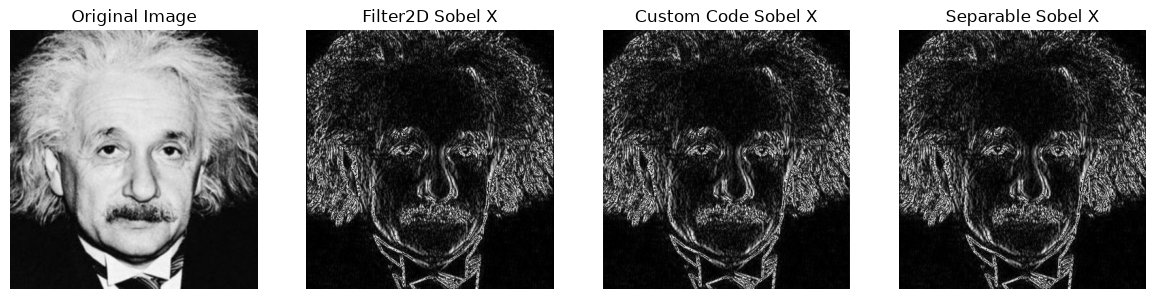

Are all three mathematical methods identical? False


In [13]:
image_path = 'C:/Users/PC/University/Semester_5/Image Processing and Machne Vision/Assignment_1/einstein.jpeg'
img_orig = cv.imread(image_path, cv.IMREAD_GRAYSCALE)
assert img_orig is not None

def custom_sobel_filter(img, kernel):
    k_rows, k_cols = kernel.shape
    # Calculate padding needed to keep output image the same size
    pad_h, pad_w = k_rows // 2, k_cols // 2
    
    padded_img = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    
    output = np.zeros_like(img, dtype=np.float32)
    
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            region = padded_img[i : i + k_rows, j : j + k_cols]
            output[i, j] = np.sum(region * kernel)
    return output

sobel_x_kernel = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], dtype=np.float32)
gradient_1 = cv.filter2D(img_orig, cv.CV_32F, sobel_x_kernel)
gradient_1_disp = np.uint8(np.absolute(gradient_1))

gradient_2 = custom_sobel_filter(img_orig, sobel_x_kernel)
gradient_2_disp = np.uint8(np.absolute(gradient_2))

sobel_column = np.array([[1], [2], [1]], dtype=np.float32)
sobel_row = np.array([[1, 0, -1]], dtype=np.float32)

gradient_3_temp = cv.filter2D(img_orig, cv.CV_32F, sobel_column)
gradient_3 = cv.filter2D(gradient_3_temp,cv.CV_32F, sobel_row)
gradient_3_disp = np.uint8(np.absolute(gradient_3))

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

axes[0].imshow(img_orig, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(gradient_1_disp, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Filter2D Sobel X')
axes[1].axis('off')

axes[2].imshow(gradient_2_disp, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Custom Code Sobel X')
axes[2].axis('off')

axes[3].imshow(gradient_3_disp, cmap='gray', vmin=0, vmax=255)
axes[3].set_title('Separable Sobel X')
axes[3].axis('off')

plt.tight_layout()
plt.show()
is_identical = np.allclose(gradient_1, gradient_2) and np.allclose(gradient_1, gradient_3)
print(f"Are all three mathematical methods identical? {is_identical}")


The visual outputs from all three methods are completely identical, which confirms that the custom and separable implementations are mathematically correct. However, the separable filter method is highly advantageous for computational efficiency. By splitting the 3x3 2D kernel into two separate 1D kernels, the total number of multiplication operations is significantly reduced. This makes edge detection much faster, especially for larger images.

<h3><b>Q8. Image Interpolation and Zooming

A selected region of the original image was zoomed using two different techniques. The nearest neighbor interpolation and bilinear interpolation. The outputs were then displayed, so the visual quality of the two scaling methods could be evaluated.

Normalized SSD (Nearest Neighbor): 0.022004
Normalized SSD (Bilinear Interpolation): 0.017436


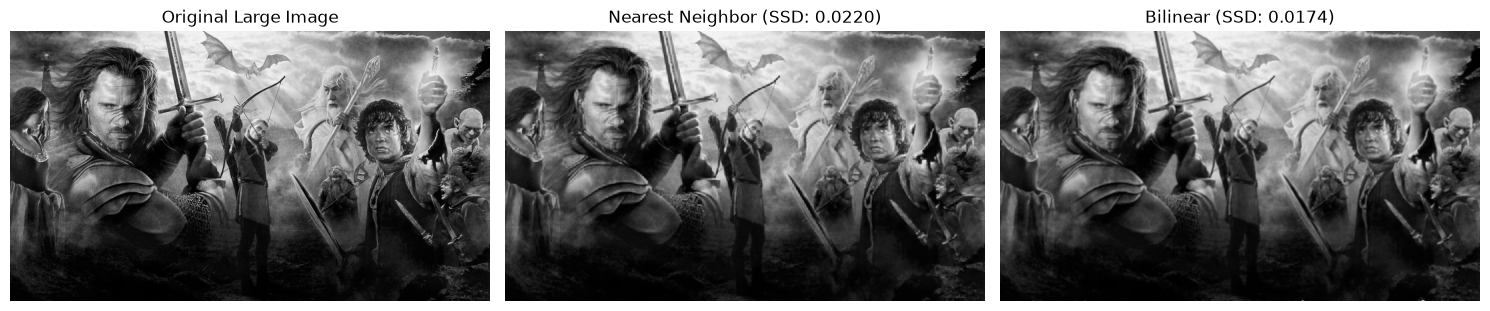

In [10]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def zoom_image(img, s, method='nearest'):
    h, w = img.shape[:2]
    new_h, new_w = int(h * s), int(w * s)
    c_new, r_new = np.meshgrid(np.arange(new_w), np.arange(new_h))
    
    c_orig = c_new / s
    r_orig = r_new / s
    
    if method == 'nearest':
        c_idx = np.clip(np.round(c_orig).astype(int), 0, w - 1)
        r_idx = np.clip(np.round(r_orig).astype(int), 0, h - 1)
        
        if len(img.shape) == 3:
            return img[r_idx, c_idx, :]
        else:
            return img[r_idx, c_idx]
            
    elif method == 'bilinear':
        c0 = np.clip(np.floor(c_orig).astype(int), 0, w - 2)
        r0 = np.clip(np.floor(r_orig).astype(int), 0, h - 2)
        
        c1 = c0 + 1
        r1 = r0 + 1
        
        c_frac = c_orig - c0
        r_frac = r_orig - r0
        
        if len(img.shape) == 3:
            c_frac = c_frac[..., np.newaxis]
            r_frac = r_frac[..., np.newaxis]
            
        I00 = img[r0, c0]
        I01 = img[r0, c1]
        I10 = img[r1, c0]
        I11 = img[r1, c1]
        
        Ix0 = I00 * (1 - c_frac) + I01 * c_frac
        Ix1 = I10 * (1 - c_frac) + I11 * c_frac
        
        I_final = Ix0 * (1 - r_frac) + Ix1 * r_frac
        
        return I_final.astype(np.uint8)
    else:
        raise ValueError("Method must be 'nearest' or 'bilinear'")

def compute_normalized_ssd(img_orig, img_zoomed):
    img1 = img_orig.astype(np.float32)
    img2 = img_zoomed.astype(np.float32)
    
    min_h = min(img1.shape[0], img2.shape[0])
    min_w = min(img1.shape[1], img2.shape[1])
    img1 = img1[:min_h, :min_w]
    img2 = img2[:min_h, :min_w]
    
    ssd = np.sum((img1 - img2) ** 2)
    norm_factor = np.sum(img1 ** 2)
    
    if norm_factor == 0:
        return 0
    return ssd / norm_factor

small_img_path = 'C:/Users/PC/University/Semester_5/Image Processing and Machne Vision/Assignment_1/im01small.png'
large_orig_path = 'C:/Users/PC/University/Semester_5/Image Processing and Machne Vision/Assignment_1/im01.png'

small_img = cv.imread(small_img_path, cv.IMREAD_GRAYSCALE)
large_orig = cv.imread(large_orig_path, cv.IMREAD_GRAYSCALE)
assert small_img is not None and large_orig is not None, "Error: Image not found."

scale_factor = 4
zoomed_nearest = zoom_image(small_img, scale_factor, method='nearest')
zoomed_bilinear = zoom_image(small_img, scale_factor, method='bilinear')

ssd_nearest = compute_normalized_ssd(large_orig, zoomed_nearest)
ssd_bilinear = compute_normalized_ssd(large_orig, zoomed_bilinear)

print(f"Normalized SSD (Nearest Neighbor): {ssd_nearest:.6f}")
print(f"Normalized SSD (Bilinear Interpolation): {ssd_bilinear:.6f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

axes[0].imshow(large_orig, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original Large Image')
axes[0].axis('off')

axes[1].imshow(zoomed_nearest, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f'Nearest Neighbor (SSD: {ssd_nearest:.4f})')
axes[1].axis('off')

axes[2].imshow(zoomed_bilinear, cmap='gray', vmin=0, vmax=255)
axes[2].set_title(f'Bilinear (SSD: {ssd_bilinear:.4f})')
axes[2].axis('off')

plt.tight_layout()
plt.show()

When the nearest neighbor interpolation is used, adjacent pixel values are simply duplicated to fill the new space. This causes a highly blocky and pixelated appearance, especially along sharp edges. In contrast, bilinear interpolation calculates new pixel values based on a weighted average of the four closest surrounding pixels. As a result, much smoother transitions and a higher overall visual quality are achieved, although this method requires slightly more computational power.

<h3><b>Q9. Image Segmentation and Depth of Field

A binary segmentation mask was created to completely separate the foreground subject from the background. A blurring filter was then applied exclusively to the extracted background. Finally, the sharp foreground was seamlessly merged back onto the blurred background to create the final enhanced composition.

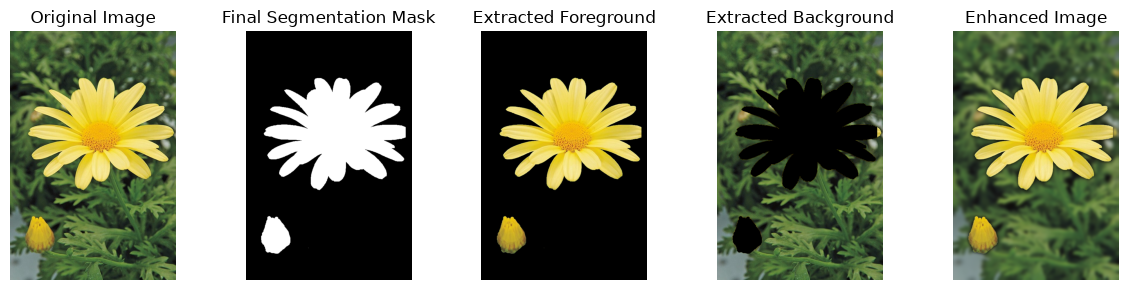

In [11]:
image_path = 'C:/Users/PC/University/Semester_5/Image Processing and Machne Vision/Assignment_1/sunflower.jpeg'
img_bgr = cv.imread(image_path)
assert img_bgr is not None, "Error: Image not found. Check the file path."

img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

mask = np.zeros(img_rgb.shape[:2], np.uint8)
bgdModel = np.zeros((1, 65), np.float64)
fgdModel = np.zeros((1, 65), np.float64)

h, w = img_rgb.shape[:2]
rect = (20, 20, w - 40, h - 40) 

cv.grabCut(img_rgb, mask, rect, bgdModel, fgdModel, 5, cv.GC_INIT_WITH_RECT)
mask2 = np.where((mask == 2) | (mask == 0), 0, 1).astype('uint8')

fg_img = img_rgb * mask2[:, :, np.newaxis]
bg_img = img_rgb * (1 - mask2)[:, :, np.newaxis]

blurred_bg = cv.GaussianBlur(bg_img, (31, 31), 0)
enhanced_img = np.where(mask2[:, :, np.newaxis] == 1, img_rgb, blurred_bg)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))

axes[0].imshow(img_rgb)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(mask2, cmap='gray')
axes[1].set_title('Final Segmentation Mask')
axes[1].axis('off')

axes[2].imshow(fg_img)
axes[2].set_title('Extracted Foreground')
axes[2].axis('off')

axes[3].imshow(bg_img)
axes[3].set_title('Extracted Background')
axes[3].axis('off')

axes[4].imshow(enhanced_img)
axes[4].set_title('Enhanced Image')
axes[4].axis('off')

plt.tight_layout()
plt.show()

When the background is blurred while the foreground remains sharp, a shallow depth of field effect is successfully simulated. This technique naturally draws visual attention directly to the main subject. It is observed that the realism of this enhancement relies entirely on the precision of the initial segmentation mask, as any errors will cause the subject's edges to blur unnaturally.

<h3><b>Q10. Edge-Preserving Smoothing with Bilateral Filters

Two different smoothing techniques were applied to the original image. A standard Gaussian filter and a Bilateral filter is used. The outputs were then displayed, so the noise reduction and edge preserving capabilities of each method could be directly compared.

Mean Squared Error (OpenCV vs Custom Bilateral): 87.2815


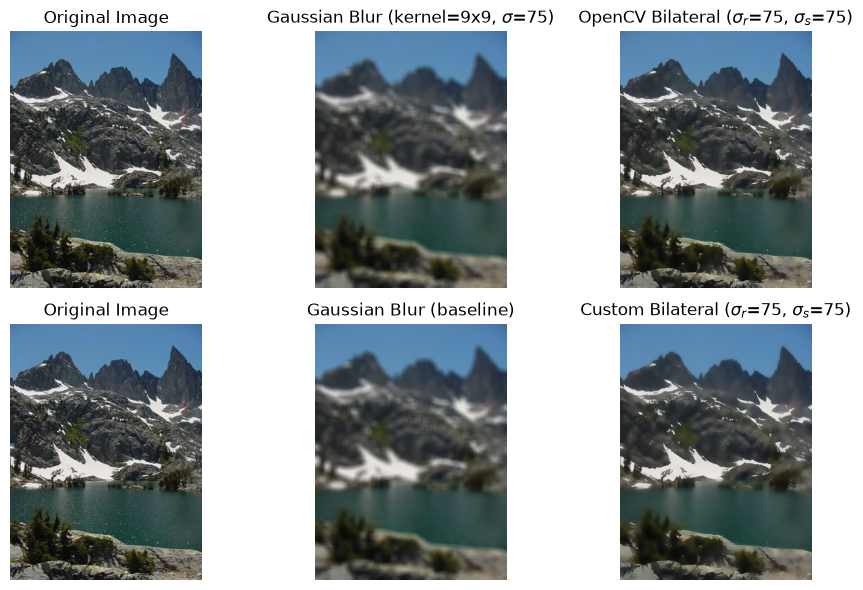

In [12]:
def custom_bilateral_filter(img, d, sigma_r, sigma_s):
    img_f = img.astype(np.float32)
    r = d // 2
    h, w, c = img_f.shape
    img_pad = np.pad(img_f, ((r, r), (r, r), (0, 0)), mode='reflect')
    output = np.zeros_like(img_f)
    w_sum = np.zeros((h, w, 1), dtype=np.float32)
    for dx in range(-r, r + 1):
        for dy in range(-r, r + 1):
            spatial_w = np.exp(-(dx**2 + dy**2) / (2 * (sigma_s**2)))
            shifted_region = img_pad[r + dx : r + dx + h, r + dy : r + dy + w, :]
            color_diff_sq = np.sum((shifted_region - img_f)**2, axis=-1, keepdims=True)
            range_w = np.exp(-color_diff_sq / (2 * (sigma_r**2)))
            weight = spatial_w * range_w
            output += shifted_region * weight
            w_sum += weight
    output = output / w_sum
    return np.clip(output, 0, 255).astype(np.uint8)

def compute_mse(imageA, imageB):
    err = np.sum((imageA.astype("float") - imageB.astype("float")) ** 2)
    err /= float(imageA.shape[0] * imageA.shape[1])
    return err

image_path = 'C:/Users/PC/University/Semester_5/Image Processing and Machne Vision/Assignment_1/lake.jpeg'
img_bgr = cv.imread(image_path)
assert img_bgr is not None, "Error: Image not found. Check the file path."

img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

d = 9
sigma_r = 75
sigma_s = 75

img_gaussian = cv.GaussianBlur(img_rgb, (d, d), sigmaX=sigma_s)
img_bilateral_cv = cv.bilateralFilter(img_rgb, d, sigmaColor=sigma_r, sigmaSpace=sigma_s)
img_bilateral_custom = custom_bilateral_filter(img_rgb, d, sigma_r, sigma_s)

mse_score = compute_mse(img_bilateral_cv, img_bilateral_custom)
print(f"Mean Squared Error (OpenCV vs Custom Bilateral): {mse_score:.4f}")

fig, axes = plt.subplots(2, 3, figsize=(10, 6))

axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

axes[0, 1].imshow(img_gaussian)
axes[0, 1].set_title(rf'Gaussian Blur (kernel={d}x{d}, $\sigma$={sigma_s})')
axes[0, 1].axis('off')

axes[0, 2].imshow(img_bilateral_cv)
axes[0, 2].set_title(rf'OpenCV Bilateral ($\sigma_r$={sigma_r}, $\sigma_s$={sigma_s})')
axes[0, 2].axis('off')

axes[1, 0].imshow(img_rgb)
axes[1, 0].set_title('Original Image')
axes[1, 0].axis('off')

axes[1, 1].imshow(img_gaussian)
axes[1, 1].set_title(rf'Gaussian Blur (baseline)')
axes[1, 1].axis('off')

axes[1, 2].imshow(img_bilateral_custom)
axes[1, 2].set_title(rf'Custom Bilateral ($\sigma_r$={sigma_r}, $\sigma_s$={sigma_s})')
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

When the standard Gaussian filter is applied, the entire image is uniformly smoothed, which causes important structural boundaries to lose their sharpness. In contrast, the Bilateral filter takes both spatial distance and pixel intensity differences into account. As a result, flat regions are effectively blurred to reduce noise, while sharp edges and fine details are successfully protected and preserved.